# LeRobot Data Profiler (PySpark)

Profile any LeRobotDataset v3 folder to see whether it is sound enough to train on, and where it deviates from what its metadata claims. Built against PushT, then run on aloha_sim and an SO-101 dataset to compare sim and real.

## Setup

In [4]:
import os, glob
from pyspark.sql import SparkSession

spark = (SparkSession
            .builder
                .master("local[*]")
                .appName("paida")
                .config("spark.driver.memory", "16g")
                .getOrCreate())

Spark's own glob did not match the local Hugging Face cache path in this environment (cause not diagnosed). <br>
Python's `glob` expands each pattern into an explicit file list, which is passed to Spark. `ROOT` is the only value that changes per dataset.

In [5]:
import os

REPO_ID = "lerobot/aloha_sim_insertion_human"               # the only line to change per dataset
DATASET_NAME = REPO_ID.split("/")[1]
ROOT = os.path.expanduser(f"~/.cache/huggingface/lerobot/{REPO_ID}")


def files(sub):
    return glob.glob(f"{ROOT}/{sub}")

data_files = files("data/*/*.parquet")
episode_files = files("meta/episodes/*/*.parquet")
info_file = f"{ROOT}/meta/info.json"
video_files = files("videos/*/*/*.mp4")

#print(episode_files)

## A. Dataset overview
**Goal:** know the shape of the dataset before measuring anything.<br>
**Details:** declared fps, total_episodes, total_frames, total_tasks. Declared shape and names of `action` and `observation.state`. The camera features.<br>
**Hint:** `features.action.shape` and `.names` come out of nested struct fields. If names is null, the dataset does not name its joints.<br>

In [6]:
#spark.conf.set("spark.sql.debug.maxToStringFields", 1000)

meta_df = (spark
            .read
            .option("multiline", "true")
            .json(info_file))
#meta_df.select("features").show(truncate=False)
meta_df.printSchema()

root
 |-- chunks_size: long (nullable = true)
 |-- codebase_version: string (nullable = true)
 |-- data_path: string (nullable = true)
 |-- features: struct (nullable = true)
 |    |-- action: struct (nullable = true)
 |    |    |-- dtype: string (nullable = true)
 |    |    |-- fps: double (nullable = true)
 |    |    |-- names: struct (nullable = true)
 |    |    |    |-- motors: array (nullable = true)
 |    |    |    |    |-- element: string (containsNull = true)
 |    |    |-- shape: array (nullable = true)
 |    |    |    |-- element: long (containsNull = true)
 |    |-- episode_index: struct (nullable = true)
 |    |    |-- dtype: string (nullable = true)
 |    |    |-- fps: double (nullable = true)
 |    |    |-- names: string (nullable = true)
 |    |    |-- shape: array (nullable = true)
 |    |    |    |-- element: long (containsNull = true)
 |    |-- frame_index: struct (nullable = true)
 |    |    |-- dtype: string (nullable = true)
 |    |    |-- fps: double (nullable = t

In [7]:
meta_df.selectExpr("total_episodes", "total_frames", "total_tasks", "fps", 
                    "features.`observation.state`.names AS state_names",
                    "features.`observation.state`.shape as state_shape",
                    "features.action.names as action_names",
                    "features.action.shape as action_shape"
                    ).show()

+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+
|total_episodes|total_frames|total_tasks|fps|         state_names|state_shape|        action_names|action_shape|
+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+
|            50|       25000|          1| 50|{[left_waist, lef...|       [14]|{[left_waist, lef...|        [14]|
+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+



## B. Episode counts and lengths
**Goal:** confirm the three sources agree on how much data there is, and see how episode length is distributed.<br>
**Details:** episode count from `info.json`, `meta/episodes` and `data`. Min, max, average length, plus percentiles. Which episodes are unusually short or long?<br>

In [8]:
episode_df = spark.read.parquet(*episode_files)
data_df = spark.read.parquet(*data_files)
episode_df.printSchema()
data_df.printSchema()

root
 |-- episode_index: long (nullable = true)
 |-- data/chunk_index: long (nullable = true)
 |-- data/file_index: long (nullable = true)
 |-- dataset_from_index: long (nullable = true)
 |-- dataset_to_index: long (nullable = true)
 |-- videos/observation.images.top/chunk_index: long (nullable = true)
 |-- videos/observation.images.top/file_index: long (nullable = true)
 |-- videos/observation.images.top/from_timestamp: double (nullable = true)
 |-- videos/observation.images.top/to_timestamp: double (nullable = true)
 |-- tasks: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- length: long (nullable = true)
 |-- stats/observation.images.top/min: array (nullable = true)
 |    |-- element: array (containsNull = true)
 |    |    |-- element: array (containsNull = true)
 |    |    |    |-- element: double (containsNull = true)
 |-- stats/observation.images.top/max: array (nullable = true)
 |    |-- element: array (containsNull = true)
 |    |    |-- element: ar

In [9]:
#episode stats from metadata
episode_df.selectExpr("count(episode_index) as total_episodes",
                        "sum(length) as total_frames",
                        "min(length) as min_ep_length",
                        "max(length) as max_ep_length",
                        "avg(length) as avg_ep_length"
                        ).show()

#episode stats from data
data_df.selectExpr("count(distinct episode_index) as total_episodes",
                    "count(frame_index) as total_frames",
                    ).show()


+--------------+------------+-------------+-------------+-------------+
|total_episodes|total_frames|min_ep_length|max_ep_length|avg_ep_length|
+--------------+------------+-------------+-------------+-------------+
|            50|       25000|          500|          500|        500.0|
+--------------+------------+-------------+-------------+-------------+

+--------------+------------+
|total_episodes|total_frames|
+--------------+------------+
|            50|       25000|
+--------------+------------+



### Per-episode cross-check: 
Matching totals don’t prove each episode matches.<br> 
One episode with extra frames and another with missing frames would cancel out. Compare each episode’s length to its frame count in data.

In [10]:
# Verify frames per episode between the metadata and data
import pyspark.sql.functions as F

(episode_df.groupBy("episode_index").agg(F.sum("length").alias("frame_count"))
.exceptAll(
data_df.groupBy("episode_index").agg(F.count("frame_index").alias("frame_count"))
)).count()

0

### Episode length distribution

Goal: find episodes with unusual lengths, meaning much shorter or longer than the rest, so they can be inspected. The plot sorts all episodes by length (frames), so the shortest sit on the left and the longest on the right. A flat middle means most episodes are similar; sharp bends at either end mark the unusual ones.

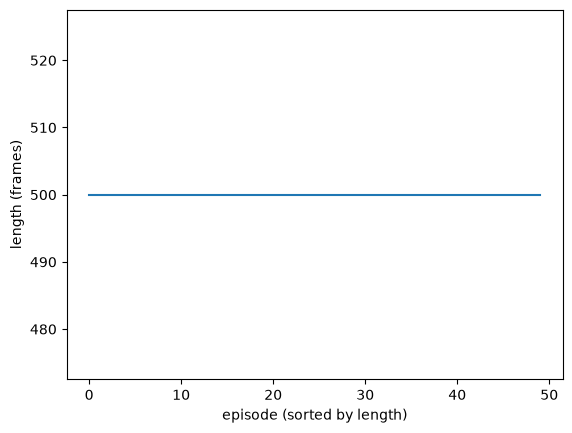

In [11]:
# one-time: uv add --dev matplotlib
import matplotlib.pyplot as plt

lengths = [r["length"] for r in episode_df.select("length").orderBy("length").collect()]

plt.plot(lengths)
plt.xlabel("episode (sorted by length)")
plt.ylabel("length (frames)")
plt.show()

25th percentile: 500 frames
50th percentile: 500 frames
75th percentile: 500 frames


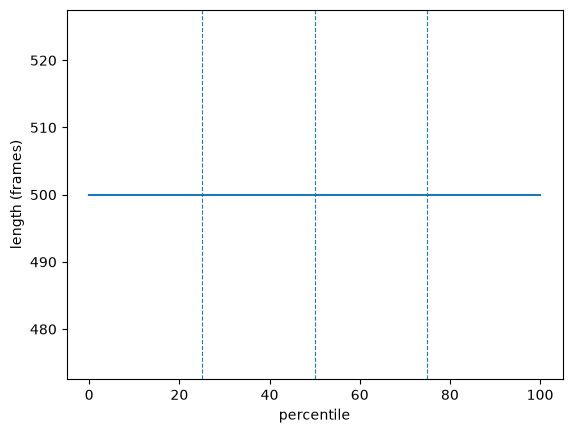

In [12]:
import pyspark.sql.functions as F
import matplotlib.pyplot as plt

pcts = [i / 100 for i in range(0, 101)]          # 0.00, 0.01, ... 1.00
#print(len(pcts))
vals = (episode_df
        .select(F.percentile_approx("length", pcts, 10000).alias("v"))
        .first()["v"])   
#print(vals)
plt.plot([p * 100 for p in pcts], vals)
for q in (25, 50, 75):
    plt.axvline(q, linestyle="--", linewidth=0.8)
    print(f"{q}th percentile: {vals[q]} frames")
plt.xlabel("percentile")
plt.ylabel("length (frames)")
plt.show()

### IQR (interquartile range) 
75th percentile minus 25th percentile = 148 - 99 = 49 frames.<br>

* What it measures: how spread out the middle half of your episodes is. A small IQR means episodes are all similar in length, and a large one means they vary a lot.
* Why use it instead of min and max: the shortest and longest episodes are the very ones you’re trying to judge. IQR ignores the extreme quarter at each end, so one odd episode can’t distort the yardstick.
* How it serves your goal: it gives you a ruler for “how far from normal is too far.” Instead of saying an episode looks long, you can say it’s more than some number of IQRs beyond the middle band.

In [13]:
q1 = vals[25]
q3 = vals[75]
iqr = q3 - q1
print(q1, q3, iqr)

500 500 0


### Outlier episodes (1.5 x IQR rule)

Goal: flag episodes whose length is unusually short or long, so they can be inspected before training.

- Percentiles: sorting the 206 episode lengths and reading values at each percent shows what is normal. The 25th, 50th and 75th percentiles split the episodes into four equal groups.
- IQR (interquartile range): 75th minus 25th percentile, the spread of the middle half of episodes. Extreme episodes cannot distort it.
- Fences: Q1 - 1.5 x IQR and Q3 + 1.5 x IQR. Episodes outside them are flagged. The 1.5 is a common convention, not a law.
- Flagged episodes are candidates to look at (for example in Rerun), not automatically bad data.

In [14]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(lower, upper)

outliers = (episode_df
            .filter((F.col("length") < lower) | (F.col("length") > upper))
            .select("episode_index", "length")
            .orderBy("length"))
outliers.show()

500.0 500.0
+-------------+------+
|episode_index|length|
+-------------+------+
+-------------+------+



### Inspect an episode in Rerun

Open a single episode to watch what happened, for example one flagged by the length outlier check. Run from the repo root:

    uv run lerobot-dataset-viz --repo-id lerobot/pusht --episode-index 184

- Rerun does not autoplay, so press play.
- Watch the `action` and `observation.state` lines. They sit on top of each other until the pusher presses against the block.
- Compare a flagged episode (174, 184) with one near the median (for example 100).
- Change `--repo-id` and `--episode-index` for other datasets and episodes.

## Check C: are frames evenly spaced at the declared fps?

**Goal:** for every frame, `timestamp * fps` should equal `frame_index`. Any gap means a dropped frame or jitter.

In [15]:
fps, total_frames = meta_df.select("fps", "total_frames").first()
#print(fps, total_frames)
data_df2 = data_df.withColumn("calc_fr_idx",
                    F.round(F.col("timestamp")*F.lit(fps))
                    .cast("int"))
frame_count = data_df2.where("calc_fr_idx == frame_index").count()
assert frame_count == total_frames

## D. Video windows vs frame counts

**Goal:** confirm that the video clip each episode points to is as long as the episode’s data.

**Details:** per episode and per camera, compare `to_timestamp - from_timestamp` with frame count divided by `fps`. <br> Report episodes that disagree.

In [16]:
from pyspark.sql import functions as F

fps = meta_df.first()["fps"]
cams = sorted({c[len("videos/"):-len("/from_timestamp")]
               for c in episode_df.schema.fieldNames()
               if c.startswith("videos/") and c.endswith("/from_timestamp")})
#print(cams)

# 1. frames per episode, counted from the data
frames_df = data_df.groupBy("episode_index").agg(F.count("*").alias("n_frames"))
#frames_df.show()

# 2. one column per camera: video clip length in seconds
clip_cols = [(F.col(f"`videos/{c}/to_timestamp`") - F.col(f"`videos/{c}/from_timestamp`")).alias(f"clip_{c}")
             for c in cams]
#print(clip_cols)

clips_df = episode_df.select("episode_index", *clip_cols)
#clips_df.show()

# 3. join, then compare each camera to frames / fps
df = clips_df.join(frames_df, "episode_index")
assert df.count() == frames_df.count()

# Tolerance instead of == 0: float rounding leaves tiny gaps, so allow half a frame (0.05 s at 10 fps).
# abs() because the clip can be shorter or longer than the data. Flag if the gap exceeds the tolerance.
tol = 0.5 / fps   # half a frame, in seconds
bad = [F.abs(F.col(f"`clip_{c}`") - F.col("n_frames") / fps) > tol for c in cams]
flagged_df = df.where(F.greatest(*bad)) if len(bad) > 1 else df.where(bad[0])
flagged_df.show()

+-------------+---------------------------+--------+
|episode_index|clip_observation.images.top|n_frames|
+-------------+---------------------------+--------+
+-------------+---------------------------+--------+



## E. Action: size, ranges and bad values
**Goal:** understand the label.

**Details:**
- Is every action vector the same nonzero length, and does it match the declared shape?
- Min and max per dimension across the dataset.
- Any nulls or NaNs.

In [17]:
def vec_profile(df, name):
    """Profile an array column: lengths, nulls, NaNs, per-dimension min/max."""
    c = F.col(f"`{name}`")                    # backticks: the name may contain a dot
    n = F.size(c)                             # array length per row
    summary_df = df.agg(
        F.count("*").alias("rows"),
        F.sum(c.isNull().cast("int")).alias("null_rows"),
        F.min(n).alias("min_len"),
        F.max(n).alias("max_len"),
        F.sum((n == 0).cast("int")).alias("empty_rows"),
    )
    per_dim_df = (df.select(F.posexplode(c).alias("dim", "value"))   # one row per (frame, position)
        .groupBy("dim")
        .agg(F.min("value").alias("min"),
             F.max("value").alias("max"),
             F.sum(F.isnan("value").cast("int")).alias("nan_values"),
             F.sum(F.col("value").isNull().cast("int")).alias("null_values"))
        .orderBy("dim"))
    return summary_df, per_dim_df

def declared_len(name):
    """Length declared in info.json: features.<name>.shape[0]."""
    return meta_df.select(F.col(f"features.`{name}`.shape")[0]).first()[0]

In [18]:
action_sum_df, action_dim_df = vec_profile(data_df, "action")
action_sum_df.show()
action_dim_df.show()

s = action_sum_df.first()
dec = declared_len("action")
bad_values = action_dim_df.agg(F.sum("nan_values") + F.sum("null_values")).first()[0]
ok = (s["min_len"] == s["max_len"] == dec) and s["empty_rows"] == 0 and s["null_rows"] == 0 and bad_values == 0
print("E action:", "ok" if ok else "FLAG", f"(declared length {dec})")

+-----+---------+-------+-------+----------+
| rows|null_rows|min_len|max_len|empty_rows|
+-----+---------+-------+-------+----------+
|25000|        0|     14|     14|         0|
+-----+---------+-------+-------+----------+

+---+-----------+-----------+----------+-----------+
|dim|        min|        max|nan_values|null_values|
+---+-----------+-----------+----------+-----------+
|  0| -0.2883884| 0.31753403|         0|          0|
|  1|-0.95567006|0.084368944|         0|          0|
|  2| 0.30219424|  1.2225827|         0|          0|
|  3|-0.26537868|  0.2807185|         0|          0|
|  4| -0.5445632|  0.9986215|         0|          0|
|  5|-0.41417482| 0.44178647|         0|          0|
|  6| 0.08270375|  1.1624637|         0|          0|
|  7|-0.47246608|   0.320602|         0|          0|
|  8|-0.99401957| 0.20555343|         0|          0|
|  9|0.088970885|  1.2118448|         0|          0|
| 10|-0.22089323|  0.7056312|         0|          0|
| 11|-0.44485444|  1.1458837|   

## F. Idle episodes and dead joints
**Goal:** find out whether anything moved.

**Details:** per episode and per joint, the range (max minus min) of that joint's action.
- An episode whose largest joint range is about zero is **idle**.
- A joint whose range is about zero in every episode is **dead**.

In [19]:
EPS = 1e-6   # "about zero": a range below this means no movement

# one row per (frame, joint position), then range per episode and joint
range_df = (data_df.select("episode_index", F.posexplode("action").alias("joint", "v"))
    .groupBy("episode_index", "joint")
    .agg((F.max("v") - F.min("v")).alias("range")))

print("smallest per-episode, per-joint range:", range_df.agg(F.min("range")).first()[0])

# idle episode: even its most-moving joint barely moved
idle_df = (range_df.groupBy("episode_index").agg(F.max("range").alias("max_range"))
           .where(F.col("max_range") < EPS))

# dead joint: it barely moved in any episode
dead_df = (range_df.groupBy("joint").agg(F.max("range").alias("max_range"))
           .where(F.col("max_range") < EPS))

n_idle, n_dead = idle_df.count(), dead_df.count()
print("idle episodes:", n_idle, "| dead joints:", n_dead)
print("F idle/dead:", "ok" if n_idle == 0 and n_dead == 0 else "FLAG")

smallest per-episode, per-joint range: 0.01840776950120926
idle episodes: 0 | dead joints: 0
F idle/dead: ok


## G. Observation state
**Goal:** profile the model's input the way E profiled the label.

**Details:**
- Length per row, and whether it matches the declared shape.
- Min and max per dimension.
- Nulls and NaNs.
- Is its shape the same as `action`, and what does that tell you about the robot?

In [20]:
state_sum_df, state_dim_df = vec_profile(data_df, "observation.state")
state_sum_df.show()
state_dim_df.show()

ss = state_sum_df.first()
dec_s = declared_len("observation.state")
bad_s = state_dim_df.agg(F.sum("nan_values") + F.sum("null_values")).first()[0]
ok_s = (ss["min_len"] == ss["max_len"] == dec_s) and ss["empty_rows"] == 0 and ss["null_rows"] == 0 and bad_s == 0
print("G state:", "ok" if ok_s else "FLAG", f"(declared length {dec_s})")

dec = declared_len("action")     # also defined in E; repeated so this cell runs alone
print("state size == action size:", dec_s == dec)

+-----+---------+-------+-------+----------+
| rows|null_rows|min_len|max_len|empty_rows|
+-----+---------+-------+-------+----------+
|25000|        0|     14|     14|         0|
+-----+---------+-------+-------+----------+

+---+------------+-----------+----------+-----------+
|dim|         min|        max|nan_values|null_values|
+---+------------+-----------+----------+-----------+
|  0| -0.28605697|  0.3167214|         0|          0|
|  1|       -0.96|0.075322725|         0|          0|
|  2|  0.30669677|   1.203116|         0|          0|
|  3| -0.26362535|  0.2756939|         0|          0|
|  4| -0.49300948| 0.99975324|         0|          0|
|  5| -0.42267004| 0.44105732|         0|          0|
|  6|         0.0|  1.0911053|         0|          0|
|  7| -0.47746226|  0.3204266|         0|          0|
|  8| -0.99055576| 0.20700689|         0|          0|
|  9|  0.09440229|  1.2157615|         0|          0|
| 10| -0.22565386| 0.80689096|         0|          0|
| 11|  -0.4322196|

## H. Cameras
**Goal:** know the visual inputs.

**Details:**
- How many cameras, and their resolution and fps (from the features in `info.json`).
- How many MP4 files per camera.
- Which camera columns exist in `meta/episodes`.
- Feed the camera keys into check D.

In [21]:
import os
from collections import Counter

# 1. cameras declared in info.json: features whose dtype is "video"
features = meta_df.first()["features"].asDict(recursive=True)
video_feats = {k: v for k, v in features.items() if v["dtype"] == "video"}
#print(video_feats)
for k, v in video_feats.items():
    print(k, "| shape:", v["shape"], "| info:", v.get("video_info"))

# 2. the same cameras seen from the other two sources
cams_meta = sorted(video_feats)                                   # info.json
cams_cols = sorted(cams)                                          # episode columns (from check D)
cams_disk = sorted({os.path.relpath(p, ROOT).split(os.sep)[1] for p in video_files})   # folders on disk

# 3. mp4 files per camera
mp4_per_cam = Counter(os.path.relpath(p, ROOT).split(os.sep)[1] for p in video_files)
print("mp4 files per camera:", dict(mp4_per_cam))

print("H cameras:", "ok" if cams_meta == cams_cols == cams_disk else "FLAG")
print("  info.json:", cams_meta, "| episode columns:", cams_cols, "| on disk:", cams_disk)

observation.images.top | shape: [480, 640, 3] | info: {'has_audio': False, 'video.codec': 'av1', 'video.fps': 50.0, 'video.is_depth_map': False, 'video.pix_fmt': 'yuv420p'}
mp4 files per camera: {'observation.images.top': 1}
H cameras: ok
  info.json: ['observation.images.top'] | episode columns: ['observation.images.top'] | on disk: ['observation.images.top']


## I. Outcome columns
**Goal:** find out whether the dataset carries a ready-made quality signal.

**Details:**
- Do `next.success`, `next.reward` and `next.done` vary within episodes, across episodes, or not at all?
- What fraction of episodes are marked successful?
- These are annotations, not training inputs.

In [22]:
outcome_cols = [c for c in ("next.reward", "next.done", "next.success") if c in data_df.columns]
print("present:", outcome_cols)

n_eps = episode_df.count()
for name in outcome_cols:
    c = F.col(f"`{name}`")                                   # backticks: dotted name

    # aggregate per episode first
    per_ep_df = data_df.groupBy("episode_index").agg(
        F.countDistinct(c).alias("n_distinct"),              # distinct values inside the episode
        F.max(c.cast("double")).alias("mx"))                 # highest value inside the episode

    r = per_ep_df.agg(
        F.sum((F.col("n_distinct") > 1).cast("int")).alias("varies_within"),
        F.sum((F.col("mx") > 0).cast("int")).alias("any_positive")).first()

    values = [row[0] for row in data_df.select(c).distinct().limit(10).collect()]
    print(f"{name}: values {values} | varies within {r['varies_within']}/{n_eps} episodes"
          f" | any positive in {r['any_positive']}/{n_eps} episodes")

present: ['next.done']
next.done: values [True, False] | varies within 50/50 episodes | any positive in 50/50 episodes


### I+. Per-episode reward summary
**Goal:** see whether `next.reward` separates good episodes from bad ones.

**Details:** per episode, the max, mean and final reward. Look at the spread across episodes, then at the best and worst few.

In [23]:
r = F.col("`next.reward`")

reward_df = (data_df.groupBy("episode_index").agg(
    F.max(r).alias("max_reward"),
    F.mean(r).alias("mean_reward"),
    F.max_by(r, "frame_index").alias("final_reward"),   # reward at the last frame
    F.count("*").alias("n_frames")))

# spread across the 206 episodes
reward_df.select("max_reward", "mean_reward", "final_reward").summary(
    "min", "25%", "50%", "75%", "max").show()

# worst and best five by final reward (candidates to open in Rerun)
reward_df.orderBy("final_reward").show(5)
reward_df.orderBy(F.col("final_reward").desc()).show(5)

{"ts": "2026-10-27 09:13:41.955", "level": "ERROR", "logger": "DataFrameQueryContextLogger", "msg": "[UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `next.reward` cannot be resolved. Did you mean one of the following? [`next.done`, `timestamp`, `action`, `index`, `episode_index`]. SQLSTATE: 42703", "context": {"file": "line 1 in cell [24]", "line": "", "fragment": "col", "errorClass": "UNRESOLVED_COLUMN.WITH_SUGGESTION"}, "exception": {"class": "Py4JJavaError", "msg": "An error occurred while calling o626.agg.\n: org.apache.spark.sql.AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `next.reward` cannot be resolved. Did you mean one of the following? [`next.done`, `timestamp`, `action`, `index`, `episode_index`]. SQLSTATE: 42703;\n'Aggregate [episode_index#111L], [episode_index#111L, 'max('`next.reward`) AS max_reward#862, 'avg('`next.reward`) AS mean_reward#863, 'max_by('`next.reward`, fra

AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `next.reward` cannot be resolved. Did you mean one of the following? [`next.done`, `timestamp`, `action`, `index`, `episode_index`]. SQLSTATE: 42703;
'Aggregate [episode_index#111L], [episode_index#111L, 'max('`next.reward`) AS max_reward#862, 'avg('`next.reward`) AS mean_reward#863, 'max_by('`next.reward`, frame_index#112L) AS final_reward#864, count(1) AS n_frames#865L]
+- Relation [observation.state#109,action#110,episode_index#111L,frame_index#112L,timestamp#113,next.done#114,index#115L,task_index#116L] parquet


/home/snudurupati/projects/physical-ai-data-architect/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


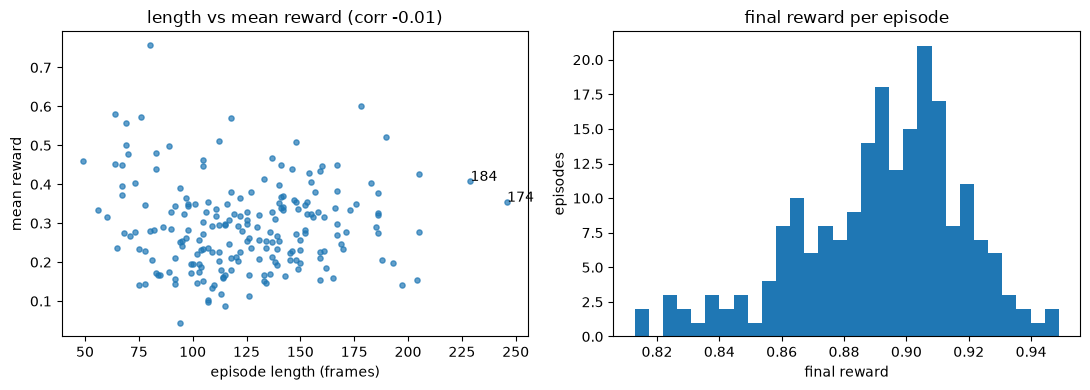

In [ ]:
import matplotlib.pyplot as plt

pdf = reward_df.toPandas()          # 206 rows
corr = pdf["n_frames"].corr(pdf["mean_reward"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: is mean reward related to episode length?
ax[0].scatter(pdf["n_frames"], pdf["mean_reward"], s=14, alpha=0.7)
for ep in (174, 184):                                    # the two length outliers
    row = pdf[pdf["episode_index"] == ep].iloc[0]
    ax[0].annotate(str(ep), (row["n_frames"], row["mean_reward"]))
ax[0].set_xlabel("episode length (frames)")
ax[0].set_ylabel("mean reward")
ax[0].set_title(f"length vs mean reward (corr {corr:.2f})")

# right: how different are the final rewards?
ax[1].hist(pdf["final_reward"], bins=30)
ax[1].set_xlabel("final reward")
ax[1].set_ylabel("episodes")
ax[1].set_title("final reward per episode")

plt.tight_layout()
plt.show()

### I++. Effort vs reward
**Goal:** test whether episodes that need more movement end with a different reward.

**Details:** per episode, path length = sum of the distance between consecutive actions. Compare it with final reward and mean reward.

**Limit:** written for 2 action dimensions (PushT). Path length is a proxy for the number of pushes, not a count.

/home/snudurupati/projects/physical-ai-data-architect/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


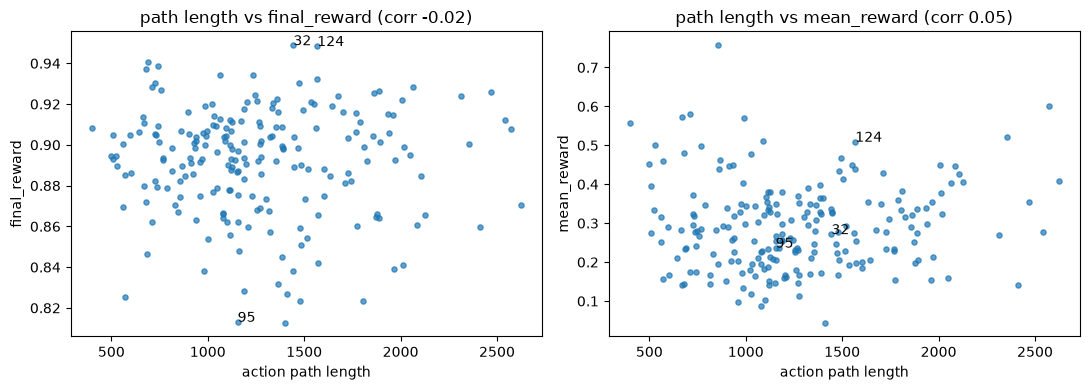

In [ ]:
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

w = Window.partitionBy("episode_index").orderBy("frame_index")
a = F.col("action")

# distance between this action and the previous one, per frame
step = F.sqrt((a[0] - F.lag(a[0]).over(w))**2 + (a[1] - F.lag(a[1]).over(w))**2)

path_df = (data_df.withColumn("step", step)
           .groupBy("episode_index")
           .agg(F.sum("step").alias("path_len")))          # first frame has a null step, which sum ignores

effort_df = reward_df.join(path_df, "episode_index")
pdf2 = effort_df.toPandas()

c_final = pdf2["path_len"].corr(pdf2["final_reward"])
c_mean = pdf2["path_len"].corr(pdf2["mean_reward"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, col, c in ((ax[0], "final_reward", c_final), (ax[1], "mean_reward", c_mean)):
    axis.scatter(pdf2["path_len"], pdf2[col], s=14, alpha=0.7)
    for ep in (95, 32, 124):                                # the episodes you inspected
        r = pdf2[pdf2["episode_index"] == ep].iloc[0]
        axis.annotate(str(ep), (r["path_len"], r[col]))
    axis.set_xlabel("action path length")
    axis.set_ylabel(col)
    axis.set_title(f"path length vs {col} (corr {c:.2f})")
plt.tight_layout()
plt.show()

## Summary and comparison
Each run saves one summary file. A final cell loads all of them into one table, so a new dataset needs only a new `DATASET_NAME` and `ROOT`.

In [ ]:
import json, pathlib

timing_mismatches = data_df.where(
    F.round(F.col("timestamp") * fps).cast("int") != F.col("frame_index")).count()   # check C
success_eps = (data_df.groupBy("episode_index")
               .agg(F.max(F.col("`next.success`").cast("int")).alias("s"))
               .where("s > 0").count()) if "next.success" in data_df.columns else None

summary = {
    "dataset": DATASET_NAME,
    "fps": fps,
    "episodes": episode_df.count(),
    "frames": data_df.count(),
    "action_size": dec,                       # from E
    "state_size": dec_s,                      # from G
    "cameras": ", ".join(cams),
    "video_codec": next(iter(video_feats.values())).get("video_info", {}).get("video.codec"),
    "timing_mismatches": timing_mismatches,   # C
    "video_window_mismatches": flagged_df.count(),   # D (your flagged_df from D)
    "idle_episodes": n_idle,                  # F
    "dead_joints": n_dead,                    # F
    "success_episodes": success_eps,          # I
}
out = pathlib.Path("results"); out.mkdir(exist_ok=True)
(out / f"{DATASET_NAME}.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "dataset": "pusht",
  "fps": 10,
  "episodes": 206,
  "frames": 25650,
  "action_size": 2,
  "state_size": 2,
  "cameras": "observation.image",
  "video_codec": "av1",
  "timing_mismatches": 0,
  "video_window_mismatches": 0,
  "idle_episodes": 0,
  "dead_joints": 0,
  "success_episodes": 0
}


In [ ]:
# Compare results across datasets
import pandas as pd, glob

rows = [json.load(open(p)) for p in sorted(glob.glob("results/*.json"))]
compare_pdf = pd.DataFrame(rows).set_index("dataset").T      # datasets as columns
compare_pdf

dataset,pusht
fps,10
episodes,206
frames,25650
action_size,2
state_size,2
cameras,observation.image
video_codec,av1
timing_mismatches,0
video_window_mismatches,0
idle_episodes,0
